In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/pokemons_analysis.csv")

variables_quanti_famd = [
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse",
    "Experience"
]

variables_quali_famd = [
    "Generation",
    "Type1",
    "Type2",
    "Legendaire"
]

variables_famd = variables_quanti_famd + variables_quali_famd

df_famd = df[variables_famd]

print("Dimensions :", df_famd.shape)

print("\nValeurs manquantes :")
print(df_famd.isna().sum())

print("\nTypes :")
print(df_famd.dtypes)

Dimensions : (1100, 11)

Valeurs manquantes :
PV                 0
Attaque            0
Defense            0
AttaqueSpeciale    0
DefenseSpeciale    0
Vitesse            0
Experience         0
Generation         0
Type1              0
Type2              0
Legendaire         0
dtype: int64

Types :
PV                 float64
Attaque            float64
Defense            float64
AttaqueSpeciale    float64
DefenseSpeciale    float64
Vitesse            float64
Experience         float64
Generation           int64
Type1               object
Type2               object
Legendaire            bool
dtype: object


In [5]:
df_famd = df[variables_famd].astype({
    variable: "string"
    for variable in variables_quali_famd
})

print(df_famd.dtypes)
print("\nValeurs manquantes :", df_famd.isna().sum().sum())

PV                        float64
Attaque                   float64
Defense                   float64
AttaqueSpeciale           float64
DefenseSpeciale           float64
Vitesse                   float64
Experience                float64
Generation         string[python]
Type1              string[python]
Type2              string[python]
Legendaire         string[python]
dtype: object

Valeurs manquantes : 0


In [6]:
import prince

print("Prince importé correctement")

Prince importé correctement


## 1. Analyse factorielle des données mixtes

La FAMD permet d'analyser simultanément des variables quantitatives et qualitatives.

Les variables quantitatives actives sont les six statistiques de combat ainsi que
l'expérience nécessaire pour atteindre le niveau 100.

Les variables qualitatives actives sont la génération, le type principal, le second
type et le statut légendaire.

La variable `Total` n'est pas incluse afin d'éviter une redondance avec les six
statistiques de combat.

In [7]:
famd = prince.FAMD(
    n_components=10,
    n_iter=3,
    random_state=42
)

famd = famd.fit(df_famd)

print("FAMD entraînée correctement")

FAMD entraînée correctement


In [8]:
famd.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,3.524,7.05%,7.05%
1,1.769,3.54%,10.59%
2,1.552,3.10%,13.69%
3,1.433,2.87%,16.56%
4,1.384,2.77%,19.33%
5,1.307,2.61%,21.94%
6,1.299,2.60%,24.54%
7,1.280,2.56%,27.10%
8,1.248,2.50%,29.59%


In [9]:
print("Valeurs propres :")
print(famd.eigenvalues_)

print("\nVariance expliquée :")
print(famd.percentage_of_variance_)

Valeurs propres :
[3.52410703 1.76942276 1.55194016 1.43329958 1.38404694 1.30715552
 1.29896424 1.27970088 1.24842756 1.20204526]

Variance expliquée :
[7.04821407 3.53884552 3.10388033 2.86659915 2.76809388 2.61431104
 2.59792848 2.55940175 2.49685513 2.40409051]


## 2. Inertie des axes

La première dimension de la FAMD explique 7,05 % de l'inertie totale et la seconde
3,54 %, soit 10,59 % pour le premier plan factoriel.

Ces valeurs sont nettement plus faibles que dans l'ACP. Cela s'explique par la présence
de plusieurs variables qualitatives possédant de nombreuses modalités, ce qui répartit
l'information sur un nombre beaucoup plus important de dimensions.

Le premier plan factoriel doit donc être interprété avec prudence : il ne résume qu'une
partie limitée de la structure globale, mais peut néanmoins mettre en évidence les
principales oppositions entre profils.

In [10]:
print("Contributions des colonnes :")
display(famd.column_contributions_.iloc[:, :5])

Contributions des colonnes :


component,0,1,2,3,4
variable,,,,,
PV,1.129025e-01,0.001299,0.014320,0.002316,0.000692
Attaque,1.359609e-01,0.008849,0.067445,0.001402,0.015009
Defense,9.800663e-02,0.200401,0.000369,0.008274,0.002348
AttaqueSpeciale,1.407697e-01,0.039148,0.048465,0.003394,0.007159
DefenseSpeciale,1.277502e-01,0.008248,0.052046,0.013943,0.002632
Vitesse,6.899574e-02,0.148054,0.000415,0.000347,0.003967
Experience,7.150098e-02,0.014146,0.038125,0.000029,0.005243
Generation_1,3.364732e-03,0.010478,0.010474,0.014365,0.017881
Generation_2,2.907354e-03,0.000196,0.001042,0.005000,0.003858


In [11]:
print("Coordonnées des colonnes :")
display(famd.column_coordinates_.iloc[:, :5])

Coordonnées des colonnes :


component,0,1,2,3,4
variable,,,,,
PV,0.630778,0.047943,-0.149075,0.057614,-0.030956
Attaque,0.692200,0.125130,-0.323527,0.044827,0.144129
Defense,0.587695,0.595478,-0.023930,-0.108902,0.057001
AttaqueSpeciale,0.704335,-0.263190,0.274252,-0.069744,-0.099538
DefenseSpeciale,0.670974,0.120810,0.284205,-0.141367,-0.060352
Vitesse,0.493101,-0.511831,-0.025371,0.022314,0.074099
Experience,0.501973,-0.158212,-0.243243,-0.006502,-0.085183
Generation_1,-0.108893,-0.136164,-0.127497,-0.143489,-0.157317
Generation_2,-0.101222,0.018633,0.040204,-0.084655,-0.073074


## 3. Interprétation des deux premiers axes

La première dimension est principalement structurée par les variables quantitatives
de combat. Les PV, l'Attaque, la Défense, l'Attaque Spéciale, la Défense Spéciale,
la Vitesse et l'Expérience contribuent ensemble à environ 75,6 % de cet axe.

Toutes ces variables sont positivement associées à Dim1. Le statut légendaire joue
également un rôle important : la modalité `Legendaire=True` est fortement positionnée
du côté positif de l'axe.

Dim1 peut donc être interprétée comme un axe de **puissance générale**, opposant les
Pokémon possédant globalement de fortes statistiques aux profils plus faibles.

La seconde dimension est principalement construite par la Défense et la Vitesse,
qui s'opposent sur l'axe. Les types Roche et Acier sont davantage associés au côté
défensif, tandis que des modalités comme Psy, Électrik ou Vol se situent davantage
du côté opposé.

Dim2 peut ainsi être interprétée comme une opposition entre des profils plutôt
**défensifs et résistants** et des profils davantage **rapides et offensifs**.

In [12]:
contrib = famd.column_contributions_.iloc[:, :5].copy()

def variable_origine(index):
    if index in variables_quanti_famd:
        return index
    if index.startswith("Generation_"):
        return "Generation"
    if index.startswith("Type1_"):
        return "Type1"
    if index.startswith("Type2_"):
        return "Type2"
    if index.startswith("Legendaire_"):
        return "Legendaire"
    return index

contrib["Variable"] = [
    variable_origine(index)
    for index in contrib.index
]

contrib_agregee = (
    contrib
    .groupby("Variable")
    .sum()
    .drop(columns=[], errors="ignore")
)

(contrib_agregee * 100).round(2)

component,0,1,2,3,4
Variable,,,,,
Attaque,13.60,0.88,6.74,0.14,1.50
AttaqueSpeciale,14.08,3.91,4.85,0.34,0.72
Defense,9.80,20.04,0.04,0.83,0.23
DefenseSpeciale,12.78,0.82,5.20,1.39,0.26
Experience,7.15,1.41,3.81,0.00,0.52
Generation,1.34,3.65,16.76,24.64,21.06
Legendaire,13.18,1.30,0.16,0.01,0.00
PV,11.29,0.13,1.43,0.23,0.07
Type1,5.09,29.66,34.54,35.82,37.82


### Contributions agrégées des variables

L'agrégation des contributions par variable confirme que Dim1 est principalement
un axe quantitatif.

Les statistiques de combat ainsi que le statut légendaire constituent l'essentiel
de la première dimension. L'Attaque Spéciale, l'Attaque, la Défense Spéciale,
les PV et le statut légendaire figurent parmi les contributions les plus importantes.

La deuxième dimension est davantage mixte : elle est fortement structurée par
`Type1` et `Type2`, ainsi que par l'opposition entre Défense et Vitesse.

Les dimensions suivantes sont encore davantage dominées par les variables qualitatives,
en particulier les types et la génération.

La FAMD complète donc l'ACP : la première dimension retrouve essentiellement la
puissance générale, tandis que les axes suivants mettent davantage en évidence
la structure des types et des générations.

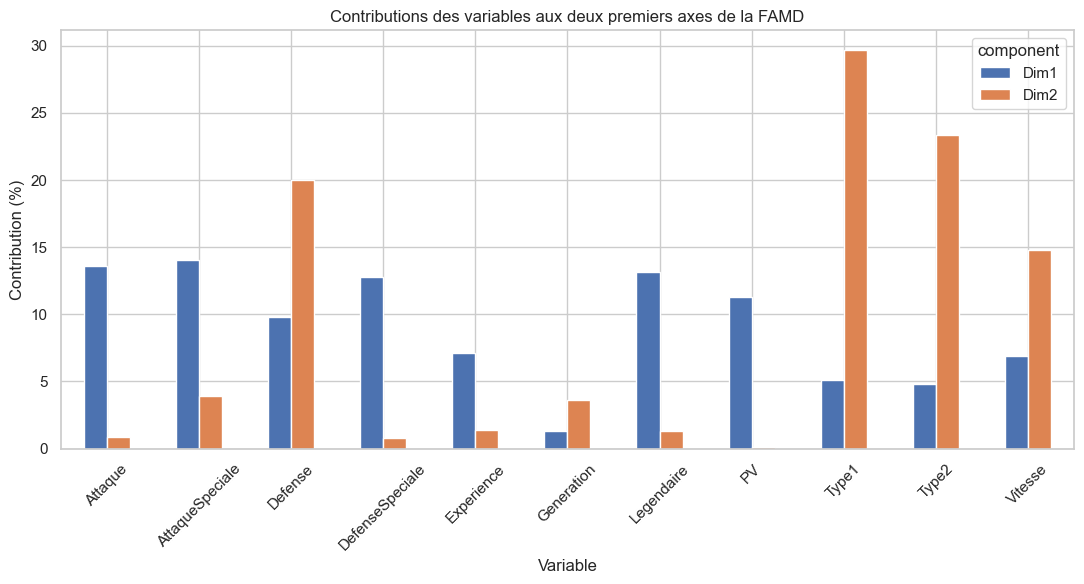

In [13]:
contrib_plot = (
    contrib_agregee[[0, 1]]
    .rename(columns={
        0: "Dim1",
        1: "Dim2"
    })
    * 100
)

contrib_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Contributions des variables aux deux premiers axes de la FAMD")
plt.xlabel("Variable")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [14]:
coord_famd = famd.row_coordinates(df_famd)

coord_famd.columns = [
    f"Dim{i+1}"
    for i in range(coord_famd.shape[1])
]

coord_famd["Nom"] = df["Nom"].values
coord_famd["Type1"] = df["Type1"].values
coord_famd["Legendaire"] = df["Legendaire"].values

coord_famd.head()

,Dim1,Dim2,Dim3,Dim4,Dim5,Dim6,Dim7,Dim8,Dim9,Dim10,Nom,Type1,Legendaire
0,-2.006366,-0.990730,0.434385,-1.876975,0.004578,2.196035,-1.501479,-2.188566,-1.995972,-0.377223,Bulbizarre,Plante,False
1,-1.034852,-0.964695,0.467887,-1.956835,0.025854,2.199790,-1.558637,-2.373626,-1.781675,-0.226440,Herbizarre,Plante,False
2,0.304247,-0.903070,0.490366,-2.064128,0.066378,2.201674,-1.637320,-2.627375,-1.494354,-0.014486,Florizarre,Plante,False
3,0.304247,-0.903070,0.490366,-2.064128,0.066378,2.201674,-1.637320,-2.627375,-1.494354,-0.014486,Florizarre Gigamax,Plante,False
4,1.419335,-0.343135,0.632791,-2.284013,0.103125,2.380268,-1.781250,-2.761580,-1.218926,0.139876,Méga-Florizarre,Plante,False


In [16]:
print("Extrêmes Dim1 positif")
display(
    coord_famd
    .nlargest(10, "Dim1")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim1 négatif")
display(
    coord_famd
    .nsmallest(10, "Dim1")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim2 positif")
display(
    coord_famd
    .nlargest(10, "Dim2")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim2 négatif")
display(
    coord_famd
    .nsmallest(10, "Dim2")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

Extrêmes Dim1 positif


,Nom,Type1,Legendaire,Dim1,Dim2
1078,Éthernatos Infinimax,Poison,True,9.884234,2.498043
966,Ultra-Necrozma,Psy,True,5.908348,-1.511464
488,Méga-Rayquaza,Dragon,True,5.863427,-1.563635
214,Méga-Mewtwo X,Psy,True,5.763419,-2.295343
786,Kyurem Blanc,Dragon,True,5.528369,-1.112284
787,Kyurem Noir,Dragon,True,5.497867,-0.554511
873,Zygarde - Forme Parfaite,Dragon,True,5.245052,1.374016
486,Primo-Groudon,Sol,True,5.235668,1.212742
215,Méga-Mewtwo Y,Psy,True,5.221817,-2.864320
1090,"Sylveroy, le Cavalier du Froid",Psy,True,5.207223,0.840504


Extrêmes Dim1 négatif


,Nom,Type1,Legendaire,Dim1,Dim2
440,Barpau,Eau,False,-3.945673,-0.423958
20,Aspicot,Insecte,False,-3.800062,-0.889780
21,Coconfort,Insecte,False,-3.659546,-0.446728
16,Chenipan,Insecte,False,-3.658711,-0.439091
909,Froussardine - Forme Solitaire,Eau,False,-3.599699,-0.419762
381,Azurill,Normal,False,-3.544507,0.210382
17,Chrysacier,Insecte,False,-3.518195,0.003961
995,Larvadar,Insecte,False,-3.516206,-0.289658
258,Tournegrin,Plante,False,-3.491156,-0.453608
233,Mimigal,Insecte,False,-3.486002,-0.046224


Extrêmes Dim2 positif


,Nom,Type1,Legendaire,Dim1,Dim2
285,Caratroc,Insecte,False,0.209085,5.684166
278,Méga-Steelix,Acier,False,1.845298,5.393608
391,Galeking,Acier,False,1.444087,4.986222
971,Ama-Ama,Roche,False,2.076179,4.889652
866,Séracrawl de Hisui,Glace,False,0.490084,4.813713
277,Steelix,Acier,False,0.703698,4.748362
390,Galegon,Acier,False,0.359109,4.495032
518,Bastiodon,Roche,False,0.112712,4.484297
389,Galekid,Acier,False,-0.725870,4.003841
392,Méga-Galeking,Acier,False,2.391779,3.930765


Extrêmes Dim2 négatif


,Nom,Type1,Legendaire,Dim1,Dim2
491,Deoxys - Forme Attaque,Psy,True,3.114996,-3.537691
1085,Regieleki,Électrik,True,2.586028,-3.445352
490,Deoxys - Forme Normale,Psy,True,3.117188,-2.914752
92,Méga-Alakazam,Psy,False,1.457030,-2.880555
215,Méga-Mewtwo Y,Psy,True,5.221817,-2.864320
780,Fulguris - Forme Totémique,Électrik,True,2.909789,-2.818670
779,Fulguris - Forme Avatar,Électrik,True,2.882118,-2.796816
89,Abra,Psy,False,-1.599955,-2.668729
90,Kadabra,Psy,False,-0.595631,-2.622511
91,Alakazam,Psy,False,0.536976,-2.543695


## 4. Interprétation des individus

Les individus extrêmes confirment l'interprétation des deux premiers axes.

Les valeurs les plus élevées sur Dim1 correspondent presque exclusivement à des
Pokémon très puissants et souvent légendaires, comme Éthernatos Infinimax,
Ultra-Necrozma, Méga-Rayquaza ou Méga-Mewtwo.

À l'inverse, les valeurs fortement négatives correspondent à des Pokémon globalement
faibles, comme Barpau, Aspicot, Chenipan ou Froussardine - Forme Solitaire.

Dim1 représente donc principalement une dimension de puissance générale.

Sur Dim2, les valeurs positives sont associées à des profils très défensifs, souvent
liés aux types Roche ou Acier, comme Caratroc, Méga-Steelix, Galeking ou Bastiodon.

Les valeurs négatives correspondent davantage à des profils rapides et orientés vers
l'offensive spéciale, comme Deoxys - Forme Attaque, Regieleki ou Méga-Alakazam.

La FAMD met ainsi en évidence à la fois un gradient de puissance globale et une
opposition entre styles de combat défensifs et rapides/offensifs.

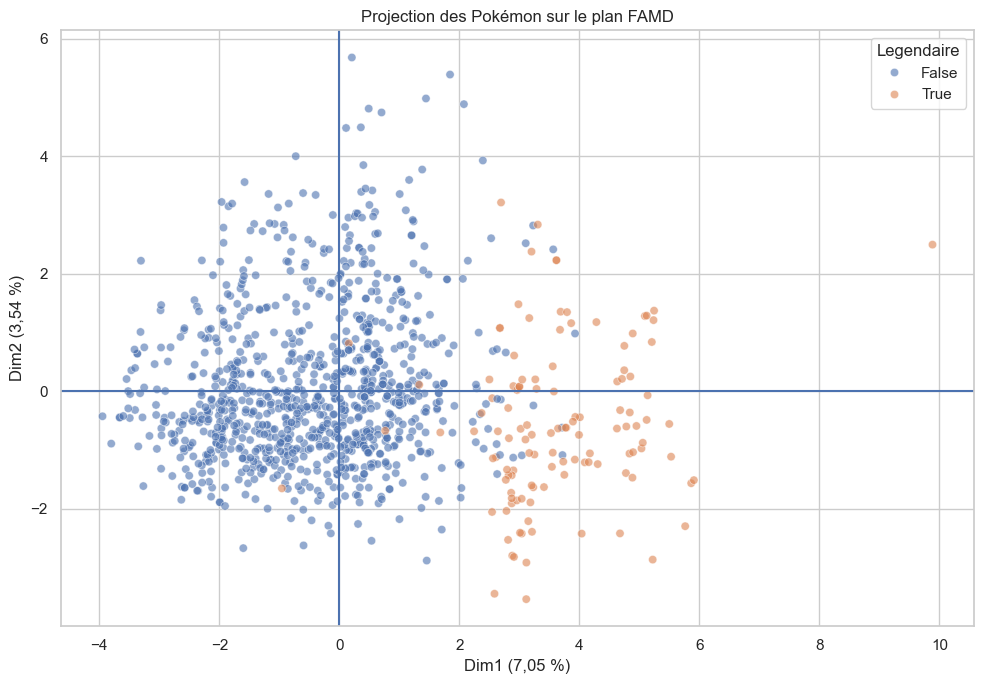

In [17]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=coord_famd,
    x="Dim1",
    y="Dim2",
    hue="Legendaire",
    alpha=0.6
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Dim1 (7,05 %)")
plt.ylabel("Dim2 (3,54 %)")
plt.title("Projection des Pokémon sur le plan FAMD")

plt.tight_layout()
plt.show()

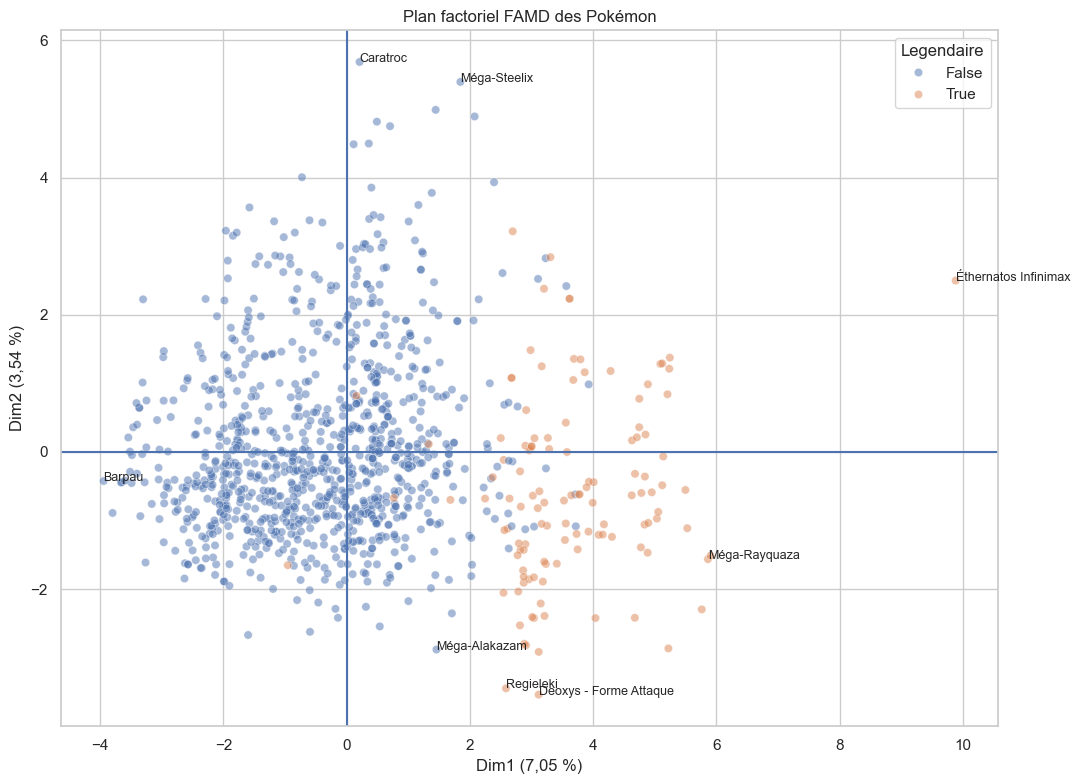

In [18]:
noms_a_afficher = [
    "Éthernatos Infinimax",
    "Méga-Rayquaza",
    "Barpau",
    "Caratroc",
    "Méga-Steelix",
    "Deoxys - Forme Attaque",
    "Regieleki",
    "Méga-Alakazam"
]

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=coord_famd,
    x="Dim1",
    y="Dim2",
    hue="Legendaire",
    alpha=0.5
)

for nom in noms_a_afficher:
    ligne = coord_famd[coord_famd["Nom"] == nom]

    if not ligne.empty:
        plt.text(
            ligne["Dim1"].iloc[0],
            ligne["Dim2"].iloc[0],
            nom,
            fontsize=9
        )

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Dim1 (7,05 %)")
plt.ylabel("Dim2 (3,54 %)")
plt.title("Plan factoriel FAMD des Pokémon")

plt.tight_layout()
plt.show()

## Conclusion de la FAMD

La FAMD permet de compléter l'ACP en intégrant simultanément des variables quantitatives
et qualitatives.

La première dimension est principalement associée à la puissance générale des Pokémon
et au statut légendaire. Les Pokémon légendaires sont globalement positionnés du côté
positif de cet axe.

La seconde dimension oppose davantage les profils défensifs, souvent associés aux types
Roche ou Acier, aux profils plus rapides et offensifs, fréquemment associés aux types
Psy ou Électrik.

Le premier plan factoriel ne représente toutefois que 10,59 % de l'inertie totale.
Les interprétations doivent donc rester prudentes et être considérées comme une synthèse
partielle de la structure globale des données.